# Kaggle step 2 · Train the conditional diffusion model on Kaggle

The same training as `03_train_diffusion.ipynb`, but on Kaggle: it keeps running in the
background ("Save Version → Save & Run All"), even if your laptop sleeps.

**Settings (right panel):** Accelerator **GPU T4 x2**, Internet **On** (needs a verified phone
number). `TILES_URL` below is the shared `tiles.zip`; then Save Version → Save & Run All.

**After it finishes (about 3–4 h):** open the run's **Output** tab and download the 4 files in
`checkpoints_diffusion/` (`best_ema.pt`, `stats.json`, `history.csv`, `config.json`). Upload
them to Google Drive in `MyDrive/kerala_hazard_vision_ai/checkpoints_diffusion/`.

In [1]:
# Shared tiles.zip on Google Drive (made by kaggle_pack_tiles).
TILES_URL = "https://drive.google.com/file/d/1WC1wOosic5MNSI44HxkPHnxxwbgibxtZ/view?usp=sharing"
REPO_URL = "https://github.com/muhammedshahidsds25-collab/kerala-hazard-vision-ai.git"
REPO_DIR = "/kaggle/working/kerala-hazard-vision-ai"

!git clone -q {REPO_URL} {REPO_DIR}
%cd {REPO_DIR}
!pip install -q . gdown

/kaggle/working/kerala-hazard-vision-ai
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [2]:
import dataclasses
import logging
import shutil
import zipfile
from pathlib import Path

import gdown
import matplotlib.pyplot as plt
import pandas as pd
import torch

from kerala_hazard_vision_ai.config import load_config
from kerala_hazard_vision_ai.train_diffusion import fit_diffusion

logging.basicConfig(level=logging.INFO, format="%(asctime)s %(message)s", force=True)
print(torch.cuda.get_device_name(0) if torch.cuda.is_available() else "No GPU: enable GPU T4 x2")

# Tiles go to /tmp: only /kaggle/working is saved as output, and it should hold just the model.
TILE_DIR = Path("/tmp/tiles")
OUT_DIR = Path("/kaggle/working/checkpoints_diffusion")
zip_path = Path("/tmp/tiles.zip")
gdown.download(TILES_URL, str(zip_path), fuzzy=True, quiet=False)
with zipfile.ZipFile(zip_path) as archive:
    archive.extractall(TILE_DIR)
zip_path.unlink()
print(f"{len(list(TILE_DIR.glob('*.npz')))} tiles ready")

Tesla T4


Downloading...
From (original): https://drive.google.com/uc?id=1WC1wOosic5MNSI44HxkPHnxxwbgibxtZ
From (redirected): https://drive.google.com/uc?id=1WC1wOosic5MNSI44HxkPHnxxwbgibxtZ&confirm=t&uuid=abf709f2-5f3d-4755-805a-0eca051260ec
To: /tmp/tiles.zip
100%|██████████| 2.53G/2.53G [00:16<00:00, 155MB/s]


2444 tiles ready


## Training

In [3]:
cfg = load_config("configs/default.yaml")
run_cfg = dataclasses.replace(
    cfg, diffusion=dataclasses.replace(cfg.diffusion, checkpoint_dir=str(OUT_DIR))
)
fit_diffusion(run_cfg, TILE_DIR, resume=False)

# The full training state (last.pt, ~0.5 GB) is not needed for evaluation: keep it out of the
# output so the download stays small.
shutil.move(OUT_DIR / "last.pt", "/tmp/last.pt")
sorted(p.name for p in OUT_DIR.iterdir())

2026-11-13 04:52:19,564 Tiles: {'train': 1730, 'val': 278, 'test': 296}
2026-11-13 04:53:22,266 Epoch 0 step 50/217: 0.96 s/step
2026-11-13 04:54:05,317 Epoch 0 step 100/217: 0.91 s/step
2026-11-13 04:54:50,437 Epoch 0 step 150/217: 0.91 s/step
2026-11-13 04:55:35,379 Epoch 0 step 200/217: 0.91 s/step
2026-11-13 04:56:16,567 Epoch 0: {'epoch': 0, 'train_loss': 0.2144, 'val_loss': 0.78701}
2026-11-13 04:57:01,860 Epoch 1 step 50/217: 0.91 s/step
2026-11-13 04:57:46,918 Epoch 1 step 100/217: 0.90 s/step
2026-11-13 04:58:31,977 Epoch 1 step 150/217: 0.90 s/step
2026-11-13 04:59:17,095 Epoch 1 step 200/217: 0.90 s/step
2026-11-13 04:59:57,912 Epoch 1: {'epoch': 1, 'train_loss': 0.07305, 'val_loss': 0.48684}
2026-11-13 05:00:43,296 Epoch 2 step 50/217: 0.91 s/step
2026-11-13 05:01:28,432 Epoch 2 step 100/217: 0.91 s/step
2026-11-13 05:02:13,560 Epoch 2 step 150/217: 0.90 s/step
2026-11-13 05:02:58,708 Epoch 2 step 200/217: 0.90 s/step
2026-11-13 05:03:39,467 Epoch 2: {'epoch': 2, 'train_los

['best_ema.pt', 'config.json', 'history.csv', 'stats.json']

## Loss curves

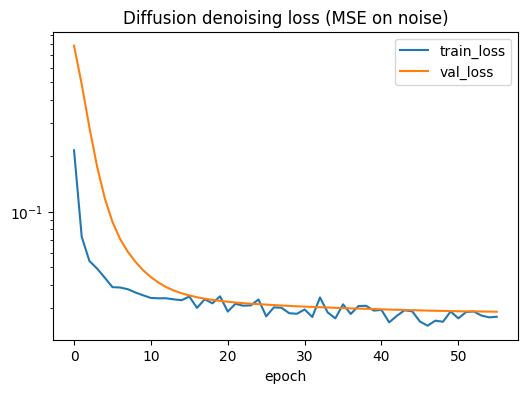

,epoch,train_loss,val_loss
51,51,0.028636,0.028885
52,52,0.028844,0.028882
53,53,0.027419,0.028834
54,54,0.026813,0.028794
55,55,0.027011,0.028756


In [4]:
history = pd.read_csv(OUT_DIR / "history.csv")
ax = history.plot(x="epoch", y=["train_loss", "val_loss"], logy=True, figsize=(6, 4),
                  title="Diffusion denoising loss (MSE on noise)")
ax.figure.savefig(OUT_DIR / "losses_diffusion.png", dpi=150)
plt.show()
history.tail()